# Module IV: Recurrent networks and LSTM
Sketches are *sequences* of pen points, so an LSTM can read them as they are drawn. Here the LSTM alone, then fused with the CNN. A second task, neural **sentiment analysis**, uses an LSTM on IMDB reviews.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, inspect
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda m: json.load(open(ROOT / "runs" / m / "results.json"))
from src.models.nets import LSTMEncoder, SketchNet
print(inspect.getsource(LSTMEncoder))

class LSTMEncoder(nn.Module):
    """Stroke-point sequence -> 128-d, reading only the valid (unpadded) steps. Module IV."""
    out_dim = 128

    def __init__(self, hidden: int = 128):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(SEQ_FEATS, 64), nn.ReLU(inplace=True))
        self.lstm = nn.LSTM(64, hidden, num_layers=2, batch_first=True, dropout=0.2)

    def forward(self, seq, length):
        out, _ = self.lstm(self.inp(seq))                       # (B, T, H); padding is after the valid steps
        idx = (length - 1).clamp(min=0).view(-1, 1, 1).expand(-1, 1, out.size(-1))
        return out.gather(1, idx).squeeze(1)



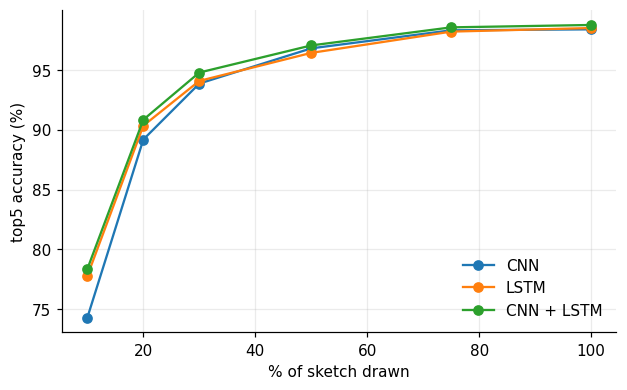

In [2]:
def curve(models, metric="top5"):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for m, label in models.items():
        r = res(m); xs = sorted(r, key=float)
        ax.plot([float(x) * 100 for x in xs], [r[x][metric] * 100 for x in xs], marker="o", label=label)
    ax.set(xlabel="% of sketch drawn", ylabel=f"{metric} accuracy (%)"); ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()
curve({'cnn': 'CNN', 'lstm': 'LSTM', 'fusion': 'CNN + LSTM'})

In [3]:
for m in ['cnn', 'lstm', 'fusion']:
    r = res(m); print(f"{m:7s} top-5 @20%: {r['0.2']['top5']:.3f}   @30%: {r['0.3']['top5']:.3f}   top-1 @30%: {r['0.3']['top1']:.3f}")

cnn     top-5 @20%: 0.892   @30%: 0.939   top-1 @30%: 0.664
lstm    top-5 @20%: 0.903   @30%: 0.941   top-1 @30%: 0.673
fusion  top-5 @20%: 0.908   @30%: 0.948   top-1 @30%: 0.682


## Sentiment analysis (IMDB, LSTM)

In [4]:
p = ROOT / 'runs' / 'sentiment' / 'results.json'
print(json.load(open(p)) if p.exists() else 'run: python -m src.train.sentiment_lstm')
from src.train.sentiment_lstm import SentimentLSTM
print(inspect.getsource(SentimentLSTM))

[{'epoch': 1, 'test_acc': 0.7309914389435126}, {'epoch': 2, 'test_acc': 0.7856458474178704}, {'epoch': 3, 'test_acc': 0.8332232808580204}, {'epoch': 4, 'test_acc': 0.8567194415598499}]
class SentimentLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, batch_first=True)
        self.out = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, 1))

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))
        return self.out(h[:, -1]).squeeze(1)

